# 3.5 · Growth at a reasonable price (GARP)

> **Needs:** the research cache with analysts' estimates (source `estimates`) and the rule set `gems-2026-11` (`eqr load-rules`, part of every build), and the database.
>
> **Produces:** registered runs of the families `garp_sp500` and `barings_qgarp`, with the hold-out opened.

**GARP** combines growth and value investing: buy companies with growing earnings and sales, but only those that are
also profitable, moderately leveraged and not expensive relative to their earnings. S&P Dow Jones Indices built it
into the **S&P 500 GARP Index** and published the rules in *Indexing GARP Strategies: A Practitioner's Guide* (July
2019). This notebook reconstructs the index from those rules on our own data and backtests it. **Part 2** runs notebook 3.6's
Barings QGARP strategy on the same S&P 500 universe, so the two GARP approaches can be compared on one universe.

**The rules** (from the paper; rebalance timing from S&P's GARP index methodology):

| Step | Rule |
|---|---|
| Universe | the S&P 500's constituents on each reference date - the last business day of May and November |
| Growth | three-year compound annual growth of earnings per share and of sales per share |
| Quality & value | return on equity, financial leverage (total debt / book equity, lower is better), earnings yield (E/P) |
| Scores | each ratio winsorized at its 2.5th / 97.5th percentiles and standardised into a z-score; the growth and quality & value scores are averages of their z-scores, capped at +/-4 (equal weights; a parameter in the first code cell) |
| Filter 1 | the 150 highest growth scores |
| Filter 2 | of those, the 75 highest quality & value scores - the top 60 always, current constituents within the top 90 retained (a buffer) |
| Weights | proportional to growth score (1 + z, or 1 / (1 - z) for negative z), capped at 5 % per stock and 40 % per sector |
| Trading | after the close on the third Friday of June and December |

**Differences from the paper:**

* **Sample period.** The paper's backtest covers 1995-2019 (Compustat). Our statements start in 2005 and growth needs
  three years of them, so this test runs from June 2009 to the end of 2024; our hold-out (2025 on) stays untouched.
* **Data.** Statements as first reported (SEC, with LSEG before it), each figure used from its publication date; the
  paper instead lags Compustat's (restated) figures by 45 days. Per-share figures use each company's own share counts.
* **Costs.** The index bears no transaction costs; this portfolio pays 0.10 % per trade, like all our large-cap
  backtests.
* **Sectors** are today's GICS sectors for every date (our sector history begins when we first recorded it); the
  40 % cap rarely binds, so this matters little.
* **Benchmark.** SPY, the S&P 500 ETF, with dividends reinvested; the paper compares with the S&P 500 total return.
* One interpretation: a return on equity that is positive only because a loss is divided by negative equity, and
  leverage over negative equity, get the **worst** score of the day. The paper's wording, "the z-score of the 2.5
  percentile ranked security", only makes sense as a penalty.

In [2]:
import pandas as pd
from IPython.display import display

from equity_research.data.cache import ResearchCache
from equity_research.data.sectors import listing_sectors
from equity_research.strategies.garp import GarpConfig, run_garp
from research_core import charts
from research_core.analytics.performance.metrics import performance
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# The weights inside each composite - equal, the published rule. Only the ratios matter; any change is our
# variant and a new registered trial (earnings to price and one quality z-score stay required whatever their
# weights).
GROWTH_WEIGHTS = {"eps_growth": 1.0, "sales_growth": 1.0}
QUALITY_VALUE_WEIGHTS = {"leverage": 1.0, "roe": 1.0, "earnings_yield": 1.0}
config = GarpConfig(  # every other setting is the published rule
    start="2004-01-01",
    end="2026-11-11",
    growth_weights=GROWTH_WEIGHTS,
    quality_value_weights=QUALITY_VALUE_WEIGHTS,
    # The run reaches into the hold-out (2025 on), so it must be opened explicitly. Opened on 2026-11-14 at the
    # owner's request: these are S&P's published rules, nothing we chose or tuned, so the look costs no research
    # choice of ours. The registry records that this run touched the hold-out.
    open_holdout=True,
)
result = run_garp(cache, config, engine=engine)
net = result.backtest.net
spy = result.benchmark.reindex(net.index)
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
print(f"{len(result.book)} rebalances, {result.book.index.min():%d %b %Y} to {result.book.index.max():%d %b %Y}")

left out 921 facts of 1 companies in ['GBP']


Registered as research run 190 - trials of this family so far: 3
45 rebalances, 18 Jun 2004 to 18 Jun 2026


## Performance

The reconstruction against SPY over the same dates, and, for scale, the paper's reported figures for 1995-2019. The
sample periods differ, so the paper's numbers are a reference point, not a target.

In [3]:
ours = pd.DataFrame({"GARP (our rebuild)": performance(net), "SPY": performance(spy)}).T
display(ours.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({"GARP against SPY": {k: m[k] for k in ACTIVE}}).T.style.format(ACTIVE))
paper = pd.DataFrame(
    {
        "S&P 500 GARP Index": {"return a year": 0.1328, "volatility": 0.1779, "return / risk": 0.75, "IR": 0.47},
        "S&P 500": {"return a year": 0.0981, "volatility": 0.1475, "return / risk": 0.67, "IR": float("nan")},
    }
).T
print("The paper, June 1995 - May 2019 (Exhibits 5 and 6):")
display(
    paper.style.format(
        {"return a year": "{:.1%}", "volatility": "{:.1%}", "return / risk": "{:.2f}", "IR": "{:.2f}"}, na_rep="-"
    )
)

,cagr,vol,sharpe,max_drawdown
GARP (our rebuild),10.8%,21.6%,0.58,-56%
SPY,10.9%,18.7%,0.65,-55%


,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
GARP against SPY,1.12,-0.9%,-0.1%,6.8%,+0.06,29%,1.6


The paper, June 1995 - May 2019 (Exhibits 5 and 6):


,return a year,volatility,return / risk,IR
S&P 500 GARP Index,13.3%,17.8%,0.75,0.47
S&P 500,9.8%,14.8%,0.67,-


,GARP,SPY,ahead of SPY
trade_date,,,
2004,+10.5%,+7.6%,+2.8%
2005,+14.4%,+4.8%,+9.6%
2006,+10.5%,+15.8%,-5.3%
2007,+20.0%,+5.1%,+14.9%
2008,-41.7%,-36.8%,-4.9%
2009,+47.8%,+26.4%,+21.4%
2010,+13.0%,+15.1%,-2.1%
2011,+4.9%,+1.9%,+3.0%
2012,+12.6%,+16.0%,-3.4%


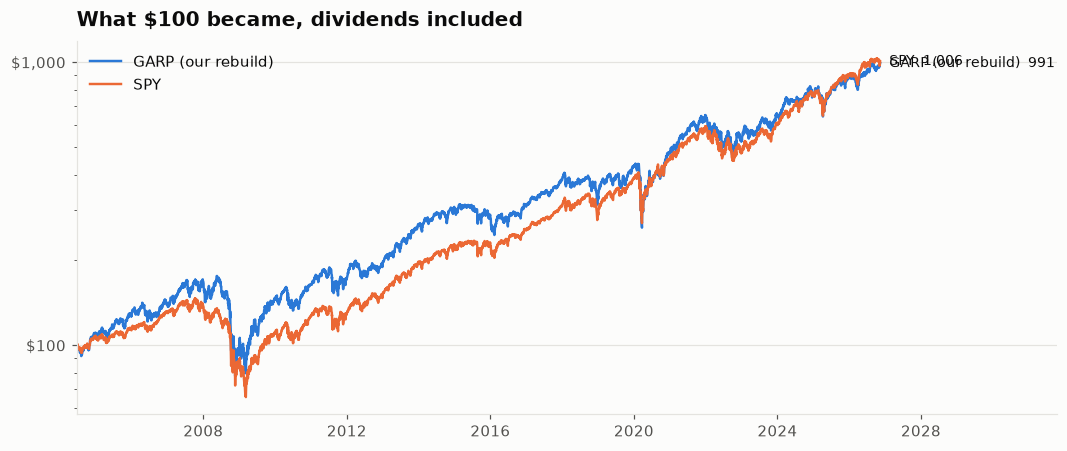

In [4]:
fig = charts.growth({"GARP (our rebuild)": net, "SPY": spy}, "What $100 became, dividends included")
years = calendar_years({"GARP": net, "SPY": spy})
years["ahead of SPY"] = years["GARP"] - years["SPY"]
display(years.style.format("{:+.1%}"))

### In sample and hold-out

The same book measured separately over the years the research could see (to the end of 2024) and over the hold-out
(from January 2025): its return, the benchmark's, and the active statistics of each period. `active_t` is the
t-statistic of the mean monthly active return - with few months, a large active return can still be noise.

In [5]:
from research_core.analytics.performance.metrics import periods_against

HOLDOUT = "2025-01-01"  # the research hold-out's first day (settings.holdout_start)
split = periods_against(net, spy, HOLDOUT)
display(split.style.format({"months": "{:.0f}", "cagr": "{:.1%}", "vol": "{:.1%}", "max_drawdown": "{:.0%}",
          "benchmark_cagr": "{:.1%}",
          "beta": "{:.2f}", "alpha": "{:+.1%}", "active_return": "{:+.1%}", "tracking_error": "{:.1%}",
          "information_ratio": "{:+.2f}", "active_t": "{:+.2f}"}))  # fmt: skip

,months,cagr,vol,max_drawdown,benchmark_cagr,beta,alpha,active_return,tracking_error,information_ratio,active_t
before 2025-01-01,247,10.4%,21.8%,-56%,10.4%,1.13,-0.9%,+0.0%,6.8%,+0.08,+0.36
from 2025-01-01,23,15.1%,18.3%,-22%,16.3%,0.90,+0.7%,-1.0%,7.7%,-0.11,-0.15


## Portfolio characteristics

The number of holdings, their concentration and the portfolio's tilts - the paper's own diagnostics (Exhibits 7 and
8): the strategy should tilt towards growth, and its sector deviations from the S&P 500 should stay moderate.

Companies held: [75]; largest single weight ever: 3.0%
Turnover: 1.6 times a year
S&P 500 members with each score on each reference date (out of about 500):


,2004-05-28,2004-11-30,2005-05-31,2005-11-30,2006-05-31,2006-11-30,2007-05-31,2007-11-30,2008-05-30,2008-11-28,2009-05-29,2009-11-30,2010-05-28,2010-11-30,2011-05-31,...,2019-11-29,2020-05-29,2020-11-30,2021-05-28,2021-11-30,2022-05-31,2022-11-30,2023-05-31,2023-11-30,2024-05-31,2024-11-29,2025-05-30,2025-11-28,2026-05-29,2026-11-11
growth score,437,448,448,451,449,445,448,449,451,449,454,456,449,452,455,...,491,489,488,494,490,494,493,496,495,497,495,496,494,494,493
quality & value score,459,461,460,462,460,459,462,464,468,470,473,468,489,490,497,...,500,498,501,503,501,498,500,503,503,500,501,502,501,502,502


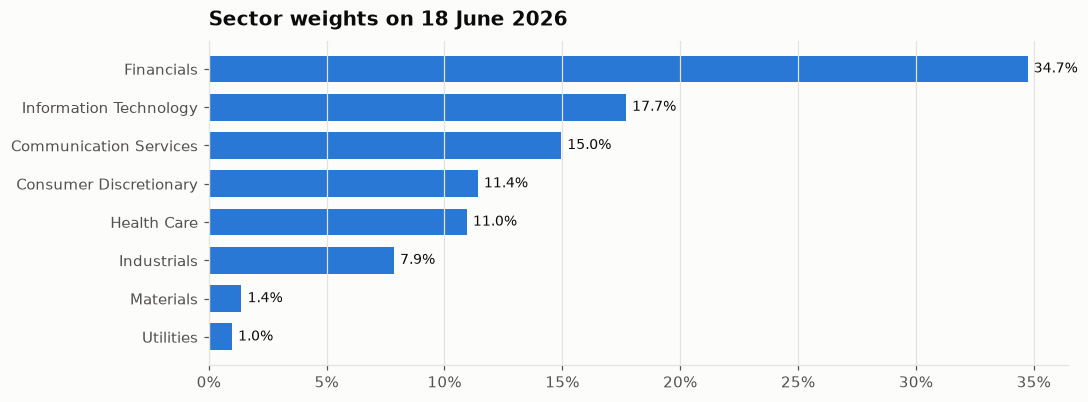

In [6]:
book = result.book
counts = sorted(set((book > 0).sum(axis=1).tolist()))
print(f"Companies held: {counts}; largest single weight ever: {book.max(axis=1).max():.1%}")
print(f"Turnover: {m['turnover']:.1f} times a year")
day = book.index[-1]
held = book.loc[day][book.loc[day] > 0]
sectors = listing_sectors(cache, held.index, day)
weights = held.groupby(sectors.reindex(held.index).to_numpy()).sum().sort_values(ascending=False)
fig = charts.ranked_bars(weights, f"Sector weights on {day:%d %B %Y}", percent=True)
refs = result.growth_z.index[result.growth_z.index.month.isin(config.reference_months)]
scored = pd.DataFrame(
    {
        "growth score": result.growth_z.loc[refs].notna().sum(axis=1),
        "quality & value score": result.quality_value_z.loc[refs].notna().sum(axis=1),
    }
)
print("S&P 500 members with each score on each reference date (out of about 500):")
display(scored.T)

## Fidelity of the reconstruction

The S&P 500 GARP Index has been calculated live since February 2019, and the Invesco S&P 500 GARP ETF (**SPGP**) has
tracked it since **24 June 2019** (before that the fund, then PXLG, tracked a Russell pure-growth index). From that
date the reconstruction can be compared with the real index. Two adjustments make the comparison like-for-like: the
reconstruction is taken **before** transaction costs (the index bears none), and SPGP's **0.36 %** annual expense
ratio is added back.

An exact reconstruction would show a daily return correlation near 1 and a tracking error near 0.

,cagr,vol,sharpe,max_drawdown
"rebuild, before costs",13.7%,22.3%,0.69,-41%
SPGP + its fee,13.6%,22.8%,0.67,-42%
SPGP as traded,13.2%,22.8%,0.66,-42%
SPY,15.4%,19.6%,0.83,-34%


Rebuild against the real index: daily correlation 0.981, beta 1.00, tracking error 4.3% a year, return gap +0.1% a year
The real index against SPY: -1.5% a year


,rebuild,real index,rebuild minus real
trade_date,,,
2019,+9.9%,+14.1%,-4.2%
2020,+13.0%,+16.1%,-3.1%
2021,+34.5%,+36.0%,-1.5%
2022,-17.7%,-13.5%,-4.2%
2023,+22.9%,+20.7%,+2.1%
2024,+17.2%,+8.9%,+8.4%
2025,+15.0%,+10.2%,+4.8%
2026,+13.1%,+13.4%,-0.3%


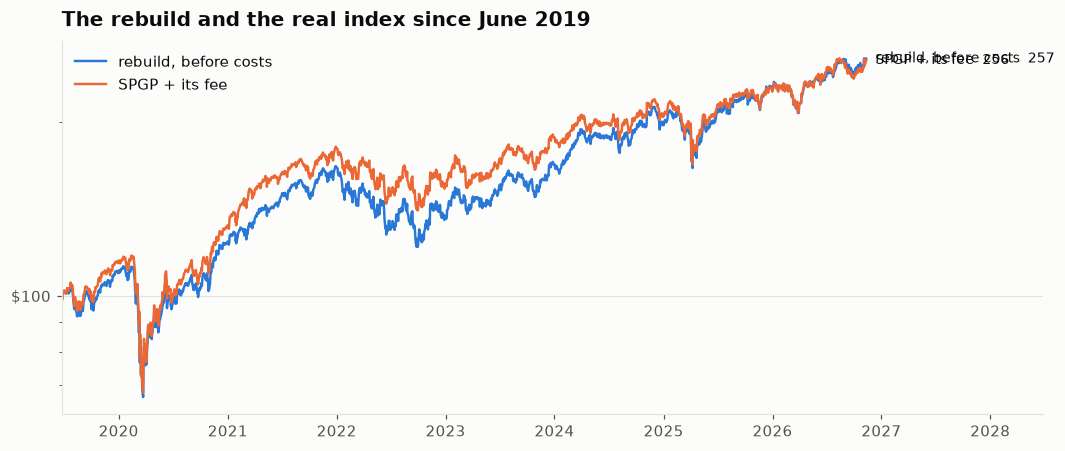

In [7]:
from equity_research.analytics.indices import vendor_returns
from research_core.analytics.performance.metrics import active_performance

since = pd.Timestamp("2019-06-24")
window = net.index[net.index >= since]
FEE = 0.0036 / 252  # SPGP's expense ratio, a trading day's share
spgp = vendor_returns(cache, "SPGP", total=True).reindex(window)
lines = {
    "rebuild, before costs": result.backtest.gross.reindex(window),
    "SPGP + its fee": spgp + FEE,
    "SPGP as traded": spgp,
    "SPY": result.benchmark.reindex(window),
}
display(
    pd.DataFrame({name: performance(r) for name, r in lines.items()}).T.style.format(
        {"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}
    )
)
closeness = active_performance(lines["rebuild, before costs"], lines["SPGP + its fee"])
both = pd.concat({"rebuild": lines["rebuild, before costs"], "index": lines["SPGP + its fee"]}, axis=1).dropna()
print(
    f"Rebuild against the real index: daily correlation {both.corr().iloc[0, 1]:.3f}, beta {closeness['beta']:.2f}, "
    f"tracking error {closeness['tracking_error']:.1%} a year, return gap {closeness['active_return']:+.1%} a year"
)
real_vs_spy = active_performance(lines["SPGP + its fee"], lines["SPY"])
print(f"The real index against SPY: {real_vs_spy['active_return']:+.1%} a year")
gaps = calendar_years({"rebuild": lines["rebuild, before costs"], "real index": lines["SPGP + its fee"]})
gaps["rebuild minus real"] = gaps["rebuild"] - gaps["real index"]
display(gaps.style.format("{:+.1%}"))
fig = charts.growth(
    {"rebuild, before costs": lines["rebuild, before costs"], "SPGP + its fee": lines["SPGP + its fee"]},
    "The rebuild and the real index since June 2019",
)

## Findings of Part 1

*Rerun on 17 November 2026 on quant_research_local (history from 2000; the rebuild still starts in June 2009), to
16 November 2026, the hold-out from January 2025
opened (S&P's published rules: nothing here was chosen by us, so the look costs no research choice).*

* **The reconstruction trails SPY.** From June 2009 to November 2026 it returned 13.2 % a year against SPY's 14.9 %,
  with higher volatility (19.2 % against 17.1 %) and a deeper maximum drawdown (-41 % against -34 %): an active
  return of -1.5 % a year and an information ratio of -0.18.
* **The hold-out says the same, more mildly.** To the end of 2024 the book returned 13.0 % a year against SPY's
  14.8 % (active return -1.6 %, t -0.78); over the 23 hold-out months 15.1 % against 16.3 % (active return -1.0 % a
  year, t -0.15) - behind by 2.9 points in 2025, ahead by 0.7 in 2026 so far. With 23 months the difference is noise;
  it does not change the verdict.
* **It does not reproduce the paper's result - but the sample period differs.** The paper's information ratio of 0.47
  covers 1995-2019, including the 2000-2002 bear market, when cheap, profitable growth stocks held up far better than
  expensive ones. Our rebuild starts in June 2009, so those years are not tested here (the database now reaches back to 2000,
  but the growth scores need three years of statements, so a rebuild could start in 2003 at the earliest - after
  the bear market); from 2009 the market was led by the largest growth companies.
* **Sources of the shortfall.** The portfolio holds 75 stocks weighted by growth score - none above 3.0 % - against a
  cap-weighted index, so it is heavily underweight the mega-caps that dominate SPY. It also tilts towards cyclical
  sectors (a beta of 1.11). Its worst years were the ones those tilts hurt: 2015 and 2018 (energy and cyclicals), 2020
  and 2024 (the mega-cap rally).
* **The reconstruction behaves as designed:** 75 holdings at every rebalance, scores for 449-497 of the 500
  constituents on each reference date (the rest lack three years of statements), and annual turnover of 1.6.

**Fidelity.** Against the real index (SPGP with its fee added back) since June 2019, the reconstruction moves with it -
a daily correlation of 0.98 and a beta of 1.00 - but not in lockstep: a tracking error of 4.3 % a year, and 0.1 % a
year more return. The gap is not stable: 1.5 to 4.2 points behind in each of 2019-2022, then 2.1, 8.4 and 4.8 points
ahead in 2023, 2024 and 2025, and level (-0.3) in 2026. So the reconstruction captures the strategy's systematic exposures
(sector tilts, beta, volatility) but at times holds a noticeably different set of stocks. Plausible causes, not yet
tested: the index uses Compustat data (EPS before unusual items, restated figures) where ours is as first reported;
its fundamentals are sampled some weeks before each reference date; and its sectors are point-in-time, ours are
today's.

**The strategy itself, not the reconstruction, underperformed.** Since June 2019 the real index trailed SPY by 1.5 %
a year, and the reconstruction (before costs) was within 0.1 % a year of the real index: over these seven years nearly all
of the shortfall is GARP's own, in a period led by the largest growth stocks.

# Part 2 · Barings QGARP on the S&P 500

Notebook 3.6 reconstructs Barings' **GEMS QGARP** score from the production code and tests a portfolio of its best
names on the S&P 1500. Part 2 runs the **same strategy on the S&P 500 only** - the large companies this notebook's
GARP index draws from - so the two GARP approaches can be compared on one universe:

* the same 118 factors, 9 composites and production's QGARP weights (0.2 alpha, 0.1 defensive, 0.3 growth,
  0.3 value, 0.1 revisions), the same cleaning limits (`gems-2026-11`), the same correction - revisions ranked the
  right way round (`FIX_REVISIONS_DIRECTION = True`, see notebook 3.6's introduction);
* the same portfolio rule: at each month end buy the top 20 % of the members by QGARP, keep a holding while it stays
  in the top 30 %, equally weighted, at the S&P 500's trading cost of 0.10 % a trade;
* measured against **SPY with its dividends**, as Part 1 is (the universe's own benchmark, the index level, leaves the
  dividends out and would flatter the strategy by about two points a year).

Composites are ranked among the day's members, so a stock's QGARP score here is its rank among the S&P 500, not the
S&P 1500: the scores, not only the universe, differ from notebook 3.6's. Each run is registered in the same family
(`barings_qgarp`) as a trial of its own. The rules, the factors and the data coverage are explained in notebook 3.6.

**The hold-out look (opened 14 November 2026).** Part 2's runs end on 11 November 2026, so they include the hold-out
from January 2025 - the 22 months no choice in notebooks 3.6 or 3.5 has seen. Every setting was fixed before the
look: production's weights and limits, the revisions direction chosen on 13 November. **What counts, written before
the run:** the screen's active return against SPY over the hold-out alone, with its t-statistic (the table *In sample
and hold-out* below). A positive active return supports the screen; a negative one with a t-statistic below -1 counts
against it. Twenty-two months are few: a genuine edge of one or two points a year would itself show a t-statistic of
about 0.5, so the look can refute a large edge, not prove a modest one. The other sections (deciles, triage) now span
2010-2026, hold-out included.

In [8]:
import pandas as pd
from IPython.display import display

from equity_research.data.cache import ResearchCache
from equity_research.strategies import barings_garp as bg
from equity_research.strategies import rules as strategy_rules
from research_core import charts
from research_core.analytics.performance.metrics import decile_returns, performance
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# QGARP's weights - production's below. Only their ratios matter (the weighted sum is ranked again), and any of
# bg.QGARP_INPUTS can be weighted: for a momentum leg, add "zscore_momentum_composite": 0.2 and scale the others by
# 0.8. Any change is a variant of Barings' rule and a new registered trial: choose the weights before seeing results.
QGARP_WEIGHTS = dict(bg.QGARP_WEIGHTS)  # production's: 0.2 alpha, 0.1 defensive, 0.3 growth, 0.3 value, 0.1 revisions
# The cleaning limits: production's export of November 2026, read from the shared rule tables (`eqr load-rules`
# writes them, the cache sync brings them here). None cleans nothing (the runs before the limits were exported);
# like the weights, the choice is part of the registered settings, so changing it is a new trial.
RULES = "gems-2026-11"
# The revisions input ranked the right way round - upgrades score best (production's code ranks it the wrong way:
# see the introduction). False reproduces production exactly. A registered setting: changing it is a new trial.
FIX_REVISIONS_DIRECTION = True
config = bg.BaringsGarpConfig(
    universe="SP500",  # the S&P 500 only: Part 2's one change from notebook 3.6
    benchmark="SPY",  # with its dividends; the S&P 500's own benchmark is the index level, without them
    start="2010-01-01",
    end="2026-11-11",  # to the latest data: through the hold-out from January 2025
    qgarp_weights=QGARP_WEIGHTS,
    rules=RULES,
    fix_revisions_direction=FIX_REVISIONS_DIRECTION,
    # The hold-out, opened on 2026-11-14 at the owner's request, once, with every setting above fixed before the
    # look and the pass mark written in the introduction. The registry records that these runs touched it.
    open_holdout=True,
)
weights = pd.Series(dict(config.qgarp_weights))
kind = "production's" if config.qgarp_weights == bg.QGARP_WEIGHTS else "a variant, not production's"
print("QGARP weights (" + kind + "):", ", ".join(f"{k} {v / weights.sum():.0%}" for k, v in weights.items()))
print("Universe:", config.universe, "| benchmark:", config.benchmark or "the universe's own")
print("Cleaning limits:", config.rules or "none")
print("Revisions ranked:", "upgrades best (corrected)" if config.fix_revisions_direction else "as production codes it")
result = bg.run_barings_garp(cache, config, engine=engine)
net = result.backtest.net
bench = result.benchmark.reindex(net.index)
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
print(f"{len(result.book)} rebalances, {result.book.index.min():%b %Y} to {result.book.index.max():%b %Y}")

QGARP weights (production's): pct_rank_quality_alpha 20%, pct_rank_quality_defensive 10%, pct_rank_growth_composite 30%, pct_rank_value_composite 30%, zscore_earnings_revisions_1_mth 10%
Universe: SP500 | benchmark: SPY
Cleaning limits: gems-2026-11
Revisions ranked: upgrades best (corrected)


left out 921 facts of 1 companies in ['GBP']
left out 921 facts of 1 companies in ['GBP']


Registered as research run 191 - trials of this family so far: 12
203 rebalances, Jan 2010 to Nov 2026


## Factors built

The library names 129 scores, three of them placeholders production never populated. Built here are 118 factors - all but one - and 9 composites.
The factors listed here are built from our data; the remainder are waiting for the data named. Coverage is the
fraction of each month's constituents with a value, averaged over months.

,factors built,factors not yet built,composites
scores,117,1,9


,factors
needs,
revenue revision counts (only EPS revision counts are loaded),1


Built factors with the lowest coverage:


,average,first date,last date
factor,,,
net_income_to_risk_weighted_assets,1%,0%,1%
capital_adequacy_ratio_tier_1_capital,1%,0%,1%
capital_adequacy_ratio_total_capital,1%,0%,1%
non_performing_loans_to_equity_and_loan_loss_provision,3%,0%,2%
net_interest_income_to_net_loan,5%,1%,3%
loans_to_deposits,5%,4%,3%
non_interest_income_to_non_interest_expense,5%,0%,5%
loan_loss_provisions_to_net_loans,5%,1%,2%
interest_income_to_interest_expense,9%,0%,3%


,average,first date,last date
factor,,,
pct_rank_value_composite,99%,95%,100%
pct_rank_value_composite_fins_neutral,99%,95%,100%
pct_rank_growth_composite,99%,94%,99%
pct_rank_quality_composite,99%,91%,99%
pct_rank_quality_alpha,99%,91%,99%
pct_rank_quality_defensive,99%,91%,99%
zscore_momentum_composite,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,86%,69%,0%
pct_rank_qgarp,100%,100%,100%


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pct_rank_value_composite,93%,97%,99%,99%,99%,99%,99%,99%,100%,99%,99%,100%,100%,100%,100%,100%,100%
pct_rank_value_composite_fins_neutral,93%,97%,99%,99%,99%,99%,99%,99%,100%,99%,99%,100%,100%,100%,100%,100%,100%
pct_rank_growth_composite,96%,98%,99%,99%,100%,99%,99%,99%,100%,99%,99%,100%,99%,100%,99%,100%,100%
pct_rank_quality_composite,93%,97%,99%,99%,99%,99%,99%,99%,100%,99%,99%,99%,99%,100%,100%,100%,99%
pct_rank_quality_alpha,93%,97%,99%,99%,99%,99%,99%,99%,100%,99%,99%,99%,99%,100%,100%,100%,99%
pct_rank_quality_defensive,93%,97%,99%,99%,99%,99%,99%,99%,100%,99%,99%,99%,99%,100%,100%,100%,99%
zscore_momentum_composite,100%,100%,100%,100%,100%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,71%,73%,75%,77%,79%,81%,84%,86%,88%,89%,92%,92%,94%,95%,96%,97%,89%


,share of rows
industry,
INDUSTRIAL,72%
OTHER FINANCIAL,13%
UTILITY,6%
INSURANCE,4%
BANK,3%
TRANSPORTATION,2%


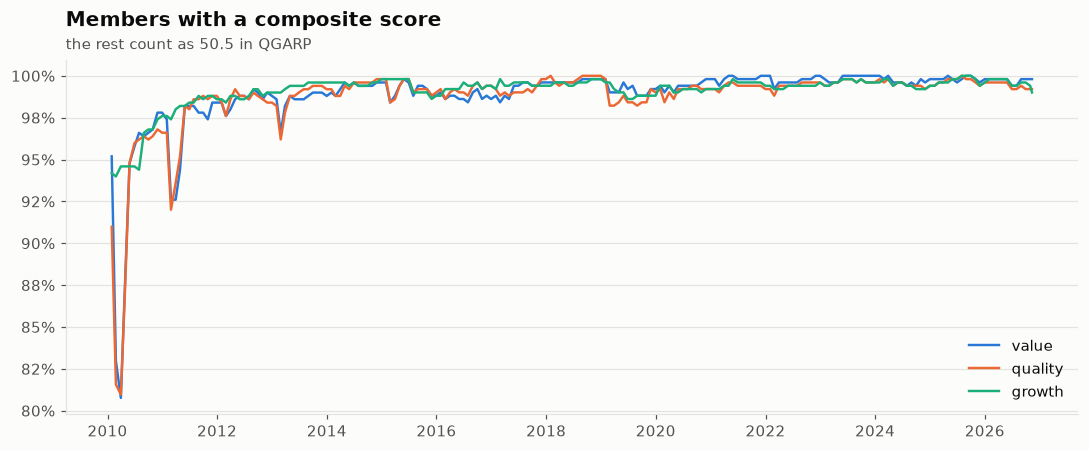

In [9]:
missing = pd.Series(bg.NOT_YET_BUILT).rename("needs").rename_axis("factor").reset_index()
display(
    pd.DataFrame(
        {"scores": [len(bg.BUILT), len(bg.NOT_YET_BUILT), len(bg.COMPOSITES)]},
        index=["factors built", "factors not yet built", "composites"],
    ).T
)
display(missing.groupby("needs").size().rename("factors").sort_values(ascending=False).to_frame())

cover = bg.coverage(result.factors, bg.BUILT)
print("Built factors with the lowest coverage:")
display(cover.sort_values("average").head(12).style.format("{:.0%}"))
display(bg.coverage(result.composites, bg.COMPOSITES).style.format("{:.0%}"))
over_time = bg.coverage_over_time(result.composites, bg.COMPOSITES[:-1])
fig = charts.lines(
    {
        "value": over_time["pct_rank_value_composite"],
        "quality": over_time["pct_rank_quality_composite"],
        "growth": over_time["pct_rank_growth_composite"],
    },
    "Members with a composite score",
    subtitle="the rest count as 50.5 in QGARP",
    percent=True,
)
display(over_time.groupby(over_time.index.year).mean().rename_axis("year").T.style.format("{:.0%}"))
display(
    result.factors["industry"].value_counts(normalize=True).rename("share of rows").to_frame().style.format("{:.0%}")
)

## Cleaning: what the limits remove

Before a factor is ranked, each value is checked against the factor's two limits; one outside them is set to
missing. The limits are a **rule set** in the database - a named collection of rules, loaded once and never changed
afterwards, so that a registered run can always say exactly which limits it used. The table counts, for the factors that lose most, the values each had before cleaning, how many lay below
the lower limit and above the upper one, and the share removed. A factor that loses a large share is either
measured differently here than in production (our line items for Worldscope's) or has limits drawn tightly on
purpose - worth reading before trusting its ranks.

A removed value is not a removed company: the stock keeps its other factors, and a composite forms from those that
remain (QGARP counts a missing composite rank as 50.5, the middle).

In [10]:
removed = result.removed
if removed is None or removed.empty:
    print("No cleaning limits in this run (RULES is None): nothing is removed")
else:
    rules = bg.shared_rules(cache, config.rules)  # from research.strategy_rule, through the cache
    sets = strategy_rules.rule_sets(cache).set_index("code")
    display(sets.loc[[config.rules], ["strategy", "rules", "loaded_at", "source"]])
    total = removed[["values", "below", "above"]].sum()
    outside = total["below"] + total["above"]
    print(f"Rule set {config.rules}: limits for {len(rules)} scores, {len(removed)} of them factors built here")
    print(
        f"{outside / total['values']:.2%} of all factor values lie outside their limits "
        f"({int(total['below']):,} below, {int(total['above']):,} above, of {int(total['values']):,})"
    )
    print(
        f"{int((removed['removed'] == 0).sum())} factors lose nothing; "
        f"{int((removed['removed'] > 0.05).sum())} lose more than 5 % of their values"
    )
    limits = rules.set_index("barings_metric_name")[["lower_limit", "upper_limit"]]
    worst = removed.join(limits).sort_values("removed", ascending=False).head(15)
    display(
        worst[["lower_limit", "upper_limit", "values", "below", "above", "removed"]].style.format(
            {
                "lower_limit": "{:,.4g}",
                "upper_limit": "{:,.4g}",
                "values": "{:,.0f}",
                "below": "{:,.0f}",
                "above": "{:,.0f}",
                "removed": "{:.1%}",
            }
        )
    )
    without = sorted(set(bg.BUILT) - set(rules["barings_metric_name"]))
    print(f"{len(without)} factors built here have no limits and are kept whole:", ", ".join(without))

,strategy,rules,loaded_at,source
code,,,,
gems-2026-11,barings_qgarp,234,2026-11-16 21:22:58,Barings' limits of November 2026 (github.com/m...


Rule set gems-2026-11: limits for 117 scores, 100 of them factors built here
0.63% of all factor values lie outside their limits (19,847 below, 39,347 above, of 9,455,989)
14 factors lose nothing; 4 lose more than 5 % of their values


,lower_limit,upper_limit,values,below,above,removed
factor,,,,,,
sales_to_ev,0,1,"98,243",132,"12,971",13.3%
operating_leverage,0,30,"84,784",0,"6,004",7.1%
payout_ratio,0,3,"101,523","4,994","1,578",6.5%
debt_to_equity,-5,5,"95,236","2,054","3,143",5.5%
free_cash_flow_conversion,-2,2,"82,971","1,085","1,215",2.8%
ebitda_to_ev,0,20,"91,423","2,290",3,2.5%
eps_growth_1_year_hist,-1,10,"100,797",752,"1,271",2.0%
sustainable_growth,-1,10,"100,744","1,616",193,1.8%
return_on_equity,-3,3,"100,784",732,965,1.7%


17 factors built here have no limits and are kept whole: accruals_year_on_year_change, capital_adequacy_ratio_tier_1_capital, capital_adequacy_ratio_total_capital, interest_income_to_interest_expense, loan_loss_provisions_to_net_loans, loans_to_deposits, market_capitalization, net_income_5_year_stability, net_income_margin_5_year_vol, net_income_to_risk_weighted_assets, net_interest_income_to_net_loan, non_interest_income_to_non_interest_expense, non_performing_loans_to_equity_and_loan_loss_provision, return_on_assets_5_year_vol, return_on_equity_5_year_vol, return_on_invested_capital_5_year_vol, sustainable_growth_3_year_average


### Do the limits change the result?

The same strategy run again without the limits (`rules=None`) - also registered, so the family's trial count and
its deflated Sharpe ratios include both. The table compares the two books; *names in common* is the share of the
with-limits book's holdings that the other book also holds, averaged over the rebalances.

In [11]:
from dataclasses import replace

if config.rules is None:
    print("This run has no limits: nothing to compare")
else:
    plain = bg.run_barings_garp(cache, replace(config, rules=None), engine=engine)
    shown = ["cagr", "vol", "sharpe", "max_drawdown", "active_return", "information_ratio", "turnover"]
    compare = pd.DataFrame(
        {
            f"with the limits (run {result.run_id})": {k: result.metrics.get(k) for k in shown},
            f"without (run {plain.run_id})": {k: plain.metrics.get(k) for k in shown},
        }
    ).T
    display(
        compare.style.format(
            {
                "cagr": "{:.1%}",
                "vol": "{:.1%}",
                "sharpe": "{:.2f}",
                "max_drawdown": "{:.0%}",
                "active_return": "{:+.1%}",
                "information_ratio": "{:+.2f}",
                "turnover": "{:.1f}",
            }
        )
    )
    held, other = result.book > 0, plain.book.reindex_like(result.book).fillna(0.0) > 0
    common = (held & other).sum(axis=1) / held.sum(axis=1)
    by_date = result.score.corrwith(plain.score, axis=1, method="spearman")  # across members, on each rebalance
    print(f"Names in common: {common.mean():.0%} on average ({common.min():.0%} to {common.max():.0%})")
    print(f"Rank correlation of the two QGARP scores across members: {by_date.mean():.3f} on average")
    print("Trials of this family now:", plain.metrics["trials"])

left out 921 facts of 1 companies in ['GBP']
left out 921 facts of 1 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,active_return,information_ratio,turnover
with the limits (run 191),13.5%,18.6%,0.77,-41%,-0.8%,-0.06,2.5
without (run 192),13.5%,18.6%,0.77,-41%,-0.8%,-0.06,2.5


Names in common: 97% on average (93% to 100%)
Rank correlation of the two QGARP scores across members: 0.995 on average
Trials of this family now: 12


### Revisions without survivorship bias

QGARP gives 10 % to earnings-estimate revisions: the *breadth* of analysts' revisions, (raised - lowered) /
estimates. In a **backtest** that input is biased: LSEG returns past revision counts only for companies still listed
today - a company since delisted or acquired answers 0 raised and 0 lowered - so only the survivors are scored on it.
(A **screen** of today's companies is not affected: they are all listed, and their counts are real.)

Two ways round it, each run and registered as a trial of the family:

* **No revisions** - the weight set to zero, the other four inputs in production's proportions.
* **Consensus revisions** - the same 10 % given to revisions measured from the consensus itself: how much the FY1
  and FY2 EPS consensus moved in the month, for the same fiscal year, over the price (Chan, Jegadeesh and
  Lakonishok, 1996). LSEG's consensus history covers the departed companies too, so this measure has no
  survivorship bias. It is ranked exactly as production ranks its revisions, so the only change is where the
  revisions come from. It stands in for breadth in this backtest only - the screen keeps production's counts.

The first table shows each revisions input's coverage of the members by year: the counts thin out the further back
the year (fewer of those companies are still listed), the consensus revisions do not.

In [12]:
from dataclasses import replace

counts_cover = result.composites[bg.REVISIONS_1_MTH].notna().groupby(result.composites["date"].dt.year).mean()
consensus_cover = (
    result.composites[bg.CONSENSUS_REVISIONS_1_MTH].notna().groupby(result.composites["date"].dt.year).mean()
)
display(
    pd.DataFrame({"revision counts (breadth)": counts_cover, "consensus revisions": consensus_cover}).T.style.format(
        "{:.0%}"
    )
)

base = dict(config.qgarp_weights)
if bg.REVISIONS_1_MTH not in base:
    print("These weights give the revisions nothing: nothing to compare")
else:
    no_revisions = {name: w for name, w in base.items() if name != bg.REVISIONS_1_MTH}
    consensus = {**no_revisions, bg.CONSENSUS_REVISIONS_1_MTH: base[bg.REVISIONS_1_MTH]}
    variants = {
        f"revision counts (run {result.run_id})": result,
    }
    for label, weights in (("no revisions", no_revisions), ("consensus revisions", consensus)):
        run = bg.run_barings_garp(cache, replace(config, qgarp_weights=weights), engine=engine)
        variants[f"{label} (run {run.run_id})"] = run
    shown = ["cagr", "vol", "sharpe", "max_drawdown", "active_return", "information_ratio", "turnover"]
    display(
        pd.DataFrame({label: {k: r.metrics.get(k) for k in shown} for label, r in variants.items()}).T.style.format(
            {
                "cagr": "{:.1%}",
                "vol": "{:.1%}",
                "sharpe": "{:.2f}",
                "max_drawdown": "{:.0%}",
                "active_return": "{:+.1%}",
                "information_ratio": "{:+.2f}",
                "turnover": "{:.1f}",
            }
        )
    )
    held = result.book > 0
    for label, run in list(variants.items())[1:]:
        other = run.book.reindex_like(result.book).fillna(0.0) > 0
        common = (held & other).sum(axis=1) / held.sum(axis=1)
        corr = result.score.corrwith(run.score, axis=1, method="spearman")
        print(
            f"{label}: {common.mean():.0%} of names in common with the revision counts' book on average, "
            f"score rank correlation {corr.mean():.3f}"
        )
    print("Trials of this family now:", list(variants.values())[-1].metrics["trials"])

date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
revision counts (breadth),72%,74%,76%,78%,79%,82%,84%,87%,88%,90%,92%,93%,95%,96%,96%,97%,90%
consensus revisions,95%,95%,96%,96%,96%,97%,97%,98%,98%,98%,98%,98%,99%,99%,99%,99%,90%


left out 921 facts of 1 companies in ['GBP']
left out 921 facts of 1 companies in ['GBP']
left out 921 facts of 1 companies in ['GBP']
left out 921 facts of 1 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,active_return,information_ratio,turnover
revision counts (run 191),13.5%,18.6%,0.77,-41%,-0.8%,-0.06,2.5
no revisions (run 193),13.0%,18.6%,0.75,-42%,-1.2%,-0.11,2.5
consensus revisions (run 194),12.7%,18.5%,0.74,-40%,-1.5%,-0.17,3.2


no revisions (run 193): 88% of names in common with the revision counts' book on average, score rank correlation 0.982
consensus revisions (run 194): 86% of names in common with the revision counts' book on average, score rank correlation 0.965
Trials of this family now: 12


## Performance

The portfolio against SPY, with its dividends, over the same dates, with the active statistics (see notebook 3.1): the information ratio
and the deflated active Sharpe ratio show whether stock selection added anything beyond market exposure.

,cagr,vol,sharpe,max_drawdown
QGARP book,13.5%,18.6%,0.77,-41%
benchmark,14.4%,17.1%,0.87,-34%


,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
QGARP against the benchmark,1.05,-1.2%,-0.8%,7.1%,-0.06,3%,2.5


,QGARP book,benchmark,difference
trade_date,,,
2010,+21.1%,+19.4%,+1.8%
2011,+3.3%,+1.9%,+1.4%
2012,+20.1%,+16.0%,+4.1%
2013,+42.8%,+32.3%,+10.5%
2014,+12.8%,+13.5%,-0.7%
2015,-4.4%,+1.3%,-5.6%
2016,+15.3%,+12.0%,+3.3%
2017,+22.3%,+21.7%,+0.6%
2018,-10.6%,-4.6%,-6.1%


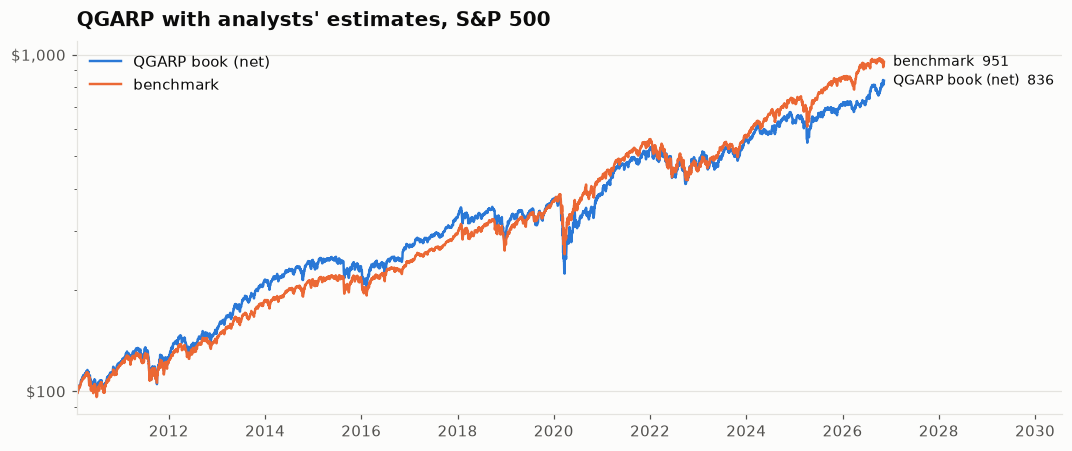

In [13]:
table = pd.DataFrame({"QGARP book": performance(net), "benchmark": performance(bench)}).T
display(table.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({"QGARP against the benchmark": {k: m.get(k) for k in ACTIVE}}).T.style.format(ACTIVE))
fig = charts.growth({"QGARP book (net)": net, "benchmark": bench}, "QGARP with analysts' estimates, S&P 500")
years = calendar_years({"QGARP book": net, "benchmark": bench})
years["difference"] = years["QGARP book"] - years["benchmark"]
display(years.style.format("{:+.1%}"))

### In sample and hold-out

The same book measured separately over the years the research could see (to the end of 2024) and over the hold-out
(from January 2025): its return, the benchmark's, and the active statistics of each period. `active_t` is the
t-statistic of the mean monthly active return - with few months, a large active return can still be noise.

In [14]:
from research_core.analytics.performance.metrics import periods_against

HOLDOUT = "2025-01-01"  # the research hold-out's first day (settings.holdout_start)
split = periods_against(net, bench, HOLDOUT)
display(split.style.format({"months": "{:.0f}", "cagr": "{:.1%}", "vol": "{:.1%}", "max_drawdown": "{:.0%}",
          "benchmark_cagr": "{:.1%}",
          "beta": "{:.2f}", "alpha": "{:+.1%}", "active_return": "{:+.1%}", "tracking_error": "{:.1%}",
          "information_ratio": "{:+.2f}", "active_t": "{:+.2f}"}))  # fmt: skip

,months,cagr,vol,max_drawdown,benchmark_cagr,beta,alpha,active_return,tracking_error,information_ratio,active_t
before 2025-01-01,179,13.2%,18.9%,-41%,14.2%,1.10,-1.9%,-0.9%,6.0%,-0.08,-0.31
from 2025-01-01,23,16.4%,16.6%,-17%,16.3%,0.49,+8.1%,+0.1%,12.9%,+0.01,+0.02


## Decile analysis of the composites

Each month the constituents are sorted into deciles by a score, and each decile's return to the next month end is
compared with the universe average (equal-weighted, before costs, annualised; `t` is its t-statistic). A score with
predictive power shows returns rising monotonically from the first decile (worst) to the tenth (best). The deciles are
only this diagnostic: the scores themselves use production's percentile ranks.

In [15]:
composite = {
    "QGARP": "pct_rank_qgarp",
    "value": "pct_rank_value_composite",
    "growth": "pct_rank_growth_composite",
    "quality alpha": "pct_rank_quality_alpha",
    "quality defensive": "pct_rank_quality_defensive",
    "momentum": "zscore_momentum_composite",
    "revisions (4 months)": "zscore_earnings_revisions_4_mth_composite",
    "consensus revisions (1 month)": bg.CONSENSUS_REVISIONS_1_MTH,
}
scores = {label: bg.score_panel(result.composites, name) for label, name in composite.items()}
deciles = pd.concat(
    {name: decile_returns(s, result.returns, result.members)["excess"] for name, s in scores.items()}, axis=1
)
display(deciles.style.format("{:+.1%}"))
spread = pd.DataFrame(
    {
        name: decile_returns(s, result.returns, result.members)
        .loc[[1, 10]]
        .assign(what=["worst tenth", "best tenth"])
        .set_index("what")["t"]
        for name, s in scores.items()
    }
)
display(spread.style.format("{:+.1f}"))

,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months),consensus revisions (1 month)
decile,,,,,,,,
1,-1.9%,+0.7%,+1.5%,-1.2%,+0.9%,-1.4%,-0.7%,-0.9%
2,+0.4%,-0.4%,-0.4%,-2.4%,+1.1%,-1.8%,-0.1%,-0.2%
3,-0.8%,-0.6%,+1.4%,-0.5%,+0.5%,+0.3%,-1.5%,+0.4%
4,-1.2%,-0.3%,-0.5%,+0.1%,+0.2%,+0.7%,-3.5%,-1.5%
5,-0.1%,-2.2%,-0.7%,-0.5%,+0.2%,-0.1%,-0.5%,-0.7%
6,+1.0%,+0.2%,-0.0%,+0.9%,-1.7%,-0.1%,+0.4%,-1.2%
7,+1.7%,+1.4%,-1.8%,+0.5%,-0.2%,+1.0%,-2.0%,+0.4%
8,+0.4%,+0.6%,-1.0%,+0.4%,+1.0%,+0.3%,-0.1%,-0.4%
9,+0.2%,-0.3%,+1.6%,+1.1%,-0.3%,-0.3%,+2.3%,+1.3%


,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months),consensus revisions (1 month)
what,,,,,,,,
worst tenth,-1.2,+0.3,+0.9,-0.8,+0.4,-0.4,-0.6,-0.3
best tenth,+0.0,+0.4,-0.1,+1.2,-1.3,+0.5,+4.3,+1.4


## Which factors predict on their own

The same triage as notebook 5.2's step 2, on QGARP's ingredients: each factor built here, each composite and the
consensus revisions, tested **alone** against the next month's return. Each month end the rank correlation (the
**IC**) between the factor and the members' next-month returns; its average over 2010-2024 with a Newey-West
t-statistic (no lags: monthly returns do not overlap), the two-sided p-value, and the Benjamini-Hochberg verdict at a
false-discovery rate of 10 % across *all* the factors tested. With over a hundred factors, about one in twenty would
pass a single test at 5 % by chance alone; the false-discovery control raises the bar to keep flukes rare.

How to read the sign: a factor keeps its own sign - a positive IC means a higher value went with a higher return
(earnings yield), a negative one that a higher value went with a lower return (debt, volatility). A composite is
turned so that higher is better, so a positive IC means it ranked the right way round. The cleaned factors are used,
as QGARP uses them. `spread` is the best fifth's next-month return less the worst fifth's, `turnover` the share of the
top fifth replaced each month, and `rank_autocorrelation` how much the ranking persists from one month to the next.

126 tested (of 127: the rest have no data); 4 are discoveries at a 10% false-discovery rate: 3 factors, 1 composites


,kind,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,,
earnings_revisions_4_mth,factor,+0.0157,+3.47,0.0005,True,+0.39%,3%,1.00
zscore_earnings_revisions_4_mth_composite,composite,+0.0154,+3.40,0.0007,True,+0.38%,3%,1.00
earnings_revisions_1_mth,factor,+0.0154,+3.40,0.0007,True,+0.38%,6%,1.00
accruals_year_on_year_change,factor,+0.0161,+3.17,0.0015,True,+0.37%,16%,0.92
earnings_revision_persistence_6mth,factor,+0.0108,+2.55,0.0108,False,+nan%,nan%,1.00
accruals,factor,-0.0138,-2.28,0.0225,False,-0.40%,9%,0.95
unusual_items_to_operating_income,factor,-0.0157,-2.04,0.0410,False,-0.13%,11%,0.96
pct_rank_quality_alpha,composite,+0.0150,+2.02,0.0433,False,+0.26%,9%,0.97
pct_rank_qgarp,composite,+0.0147,+1.79,0.0733,False,+0.07%,14%,0.95


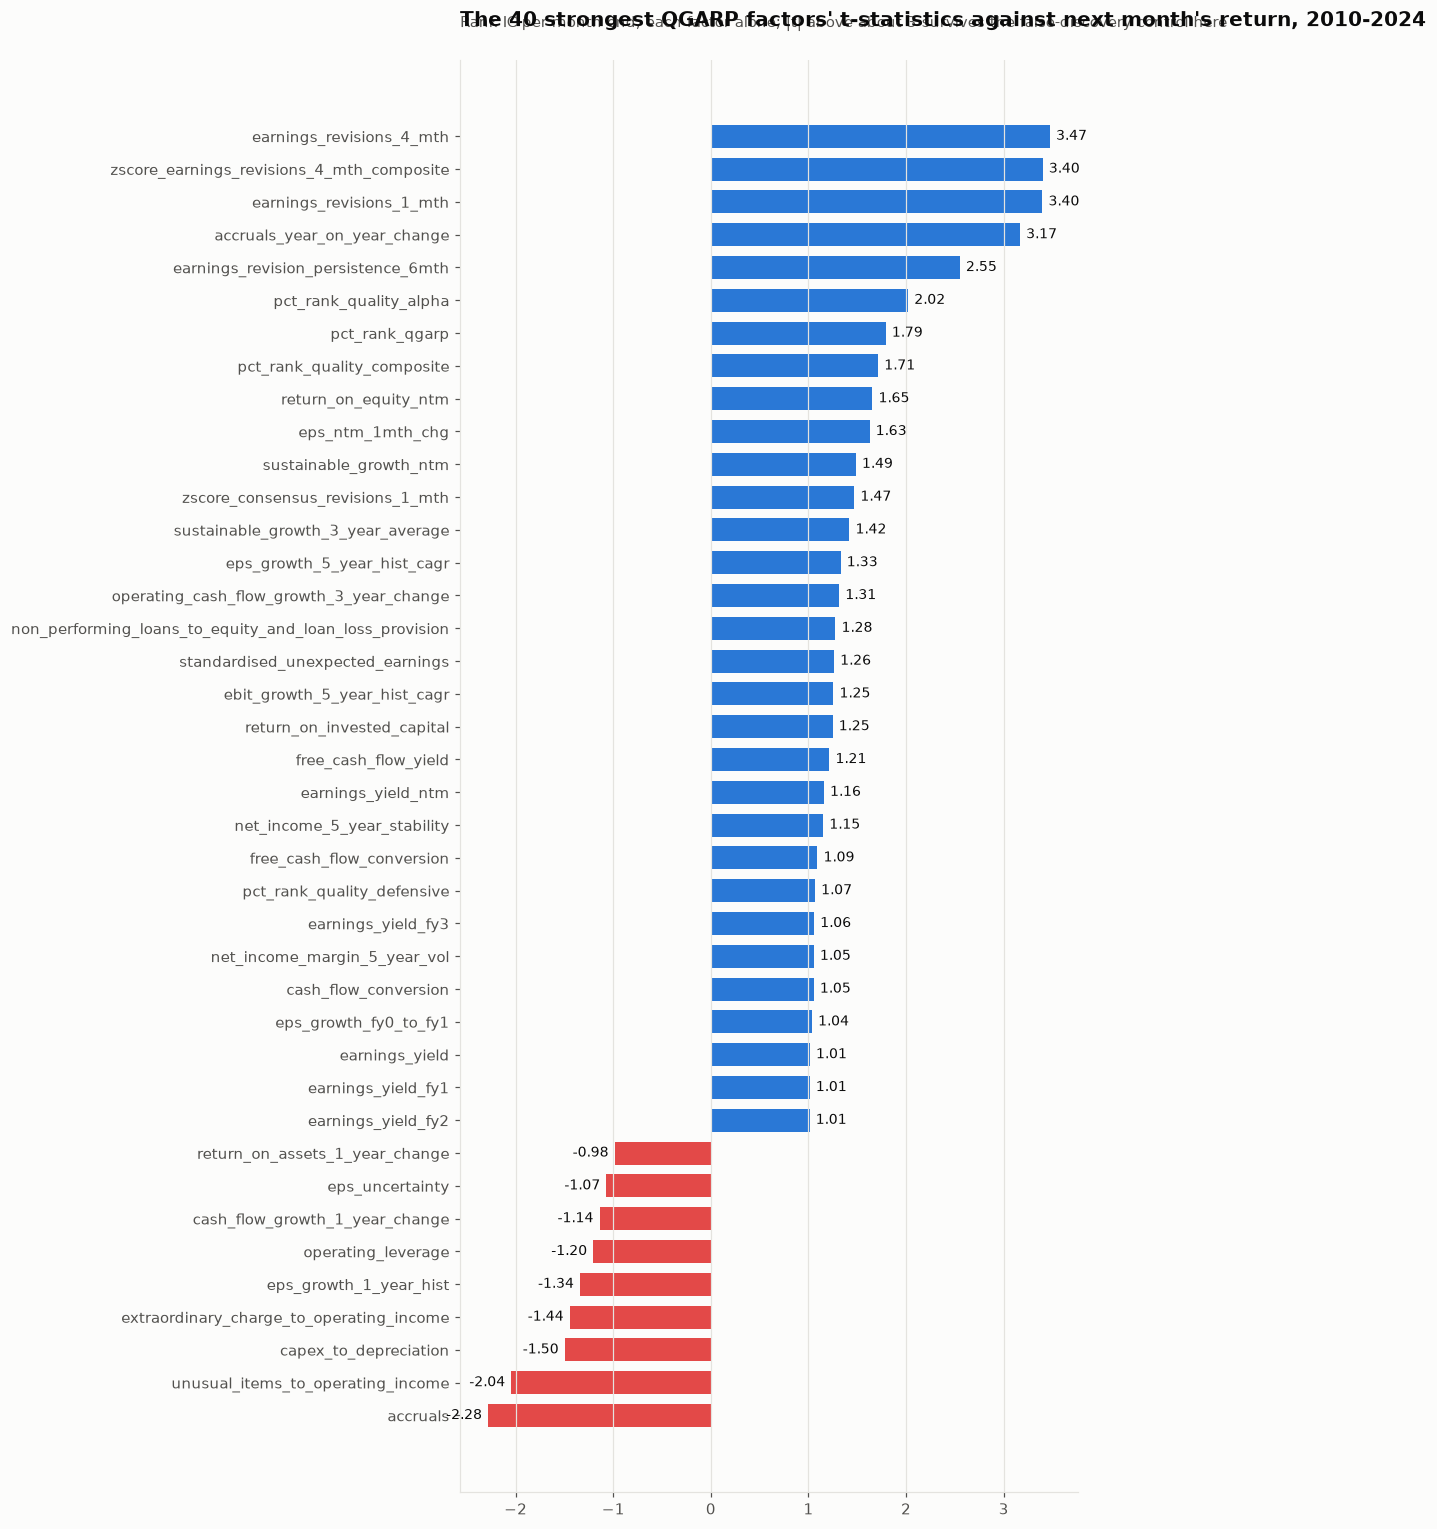

In [16]:
from research_core.analytics.signals import evaluation as ev
from research_core.analytics.signals import labels as lb

FDR = 0.10
tested = [*bg.BUILT, *bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH]
panels = bg.factor_panels(result.factors, bg.BUILT) | bg.factor_panels(
    result.composites, [*bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH]
)
next_month = lb.period_returns(result.returns, result.book.index)  # each month end's return to the next
ledger = ev.triage(panels, next_month, result.members, lags=0, q=FDR)
ledger.insert(0, "kind", ["composite" if n in (*bg.COMPOSITES, bg.CONSENSUS_REVISIONS_1_MTH) else "factor"
                          for n in ledger.index])  # fmt: skip
found = ledger[ledger["discovery"]]
print(
    f"{len(panels)} tested (of {len(tested)}: the rest have no data); {len(found)} are discoveries at a "
    f"{FDR:.0%} false-discovery rate: {len(found[found['kind'] == 'factor'])} factors, "
    f"{len(found[found['kind'] == 'composite'])} composites"
)
STYLE = {"mean_ic": "{:+.4f}", "t_nw": "{:+.2f}", "p_value": "{:.4f}", "spread": "{:+.2%}", "turnover": "{:.0%}",
         "rank_autocorrelation": "{:.2f}"}  # fmt: skip
display(ledger.style.format(STYLE))  # every factor tested, strongest first
fig = charts.ranked_bars(
    ledger["t_nw"].head(40),
    "The 40 strongest QGARP factors' t-statistics against next month's return, 2010-2024",
    subtitle="Rank IC per month end, each factor alone; |t| above about 3 survives the false-discovery control here",
)

In [17]:
# the composites and the inputs QGARP weighs, side by side
display(ledger[ledger["kind"] == "composite"].style.format(STYLE))
print(
    f"Factors with |t| >= 2 that are not discoveries: {len(ledger[(ledger['t_nw'].abs() >= 2) & ~ledger['discovery']])}"
)

,kind,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,,
zscore_earnings_revisions_4_mth_composite,composite,+0.0154,+3.40,0.0007,True,+0.38%,3%,1.00
pct_rank_quality_alpha,composite,+0.0150,+2.02,0.0433,False,+0.26%,9%,0.97
pct_rank_qgarp,composite,+0.0147,+1.79,0.0733,False,+0.07%,14%,0.95
pct_rank_quality_composite,composite,+0.0145,+1.71,0.0866,False,+0.05%,13%,0.96
zscore_consensus_revisions_1_mth,composite,+0.0115,+1.47,0.1418,False,+0.20%,67%,0.31
pct_rank_quality_defensive,composite,+0.0081,+1.07,0.2859,False,-0.15%,16%,0.95
pct_rank_growth_composite,composite,+0.0038,+0.47,0.6384,False,+0.01%,14%,0.93
pct_rank_value_composite,composite,+0.0040,+0.30,0.7624,False,+0.01%,8%,0.98
zscore_momentum_composite,composite,+0.0038,+0.27,0.7875,False,+0.18%,39%,0.72


Factors with |t| >= 2 that are not discoveries: 4


## Current holdings

The stocks held after the last rebalance, with their composite percentile ranks (1 = best).

In [18]:
last = result.book.index.max()
held = result.book.loc[last]
held = held[held > 0].index
latest = result.composites[result.composites["date"] == result.composites["date"].max()].set_index("listing_id")
names = cache.query(
    "SELECT listing_id, name FROM core.listing WHERE listing_id IN (" + ", ".join(str(int(i)) for i in held) + ")"
).set_index("listing_id")["name"]
book = latest.reindex(held)[
    ["pct_rank_qgarp", "pct_rank_quality_alpha", "pct_rank_quality_defensive", "pct_rank_value_composite"]
]
book.insert(0, "name", names.reindex(book.index))
print(f"{len(held)} names held after {last:%d %b %Y}")
display(book.sort_values("pct_rank_qgarp").head(25))

127 names held after 11 Nov 2026


,name,pct_rank_qgarp,pct_rank_quality_alpha,pct_rank_quality_defensive,pct_rank_value_composite
listing_id,,,,,
261,Marathon Petroleum Corporation,1,4,51,4
211,Deckers Outdoor Corporation,1,11,16,13
1229,Valero Energy Corp,1,3,52,6
2681,Allstate Corp,1,13,64,8
2492,Arch Capital Group Ltd.,1,21,27,5
235,"The Hartford Insurance Group, Inc.",2,25,17,8
924,Camden Property Trust,2,9,92,10
158,"The Travelers Companies, Inc.",2,18,32,15
2800,Occidental Petroleum Corp,2,30,57,3


## Findings of Part 2

*Rerun on 17 November 2026 on quant_research_local (history from 2000): notebook 3.6's QGARP - production's weights and cleaning limits,
revisions ranked the right way round - on the S&P 500 only, against SPY with its dividends, from January 2010 to
16 November 2026, the hold-out from January 2025 opened.*

**The hold-out look, against the pass mark written before the run: inconclusive.** Over the 23 hold-out months the
screen's book returned 16.4 % a year against SPY's 16.3 %: an active return of +0.1 % a year, a t-statistic of 0.02.
That is neither the positive active return that would support the screen nor the t below -1 that would count against
it - in effect a tie with SPY. It got there differently from SPY: 6.2 points behind in 2025, 6.5 ahead in 2026 so far,
with a beta of only 0.49, a tracking error of 12.9 % a year and a maximum drawdown of -17 %. Twenty-two months were
always too few to prove a modest edge; this look does not find one, and does not rule one out.

* **In sample, the same shortfall as before.** To the end of 2024 the book returned 13.2 % a year against SPY's
  14.2 % (active return -0.9 %, t -0.31). Over the whole period, 2010 to November 2026, 13.5 % against 14.4 %: an
  active return of -0.8 % a year, an information ratio of -0.06, a beta of 1.05, a maximum drawdown of -41 % against
  -34 %. The deflated active Sharpe ratio is 41 %, but it counts only the family's trials since the run registry
  was started afresh with quant_research_local on 15 November 2026 (two when the main run was registered, four by
  the end of this notebook); counting the eighteen trials of the earlier registry, it was 2 %. On the S&P 1500 (notebook 3.6, to 2024) the same strategy
  trailed SPTM by about as much.
* **It does better than the S&P 500 GARP index of Part 1** - 13.5 % a year against 13.2 %, an information ratio of
  -0.06 against -0.18 - though the two are not like for like: QGARP rebalances monthly into ~125 names, equally
  weighted; the GARP index twice a year into 75, weighted by growth score, and from June 2009.
* **The same years as on the S&P 1500.** Ahead when value stocks led - 2013 (+10.5 points), 2021 (+6.1), 2022
  (+7.6); behind when mega-cap growth led - 2015 (-5.6), 2020 (-13.8), 2023 (-7.0), 2024 (-11.8), 2025 (-6.2). An
  equally weighted book of the S&P 500 is underweight its largest companies by construction.
* **The cleaning limits change almost nothing**: 13.5 % a year with them and without; 97 % of names in common
  (rank correlation of the two scores 0.995).
* **Revisions help a little.** With the analyst counts the strategy returns 13.5 % a year (information ratio -0.06),
  without revisions 13.0 % (-0.11), with the survivorship-free consensus revisions 12.7 % (-0.17, and more
  turnover). The counts cover 72 % of members in 2010 and 96-97 % in 2024-2025 - fewer large companies have
  disappeared, so their survivorship bias is smaller here than on the S&P 1500.
* **Among large companies, little predicts on its own.** Of 126 factors and composites tested alone over 2010-2026,
  four are discoveries at a 10 % false-discovery rate: the revision measures (4-month breadth t +3.47, its composite
  +3.40, 1-month breadth +3.40 - measured on the survivors) and the year-on-year change in accruals (+3.17). Accruals
  themselves (t -2.28: profits running ahead of cash flow did worse), unusual items (-2.04) and quality's alpha half
  (+2.02) miss narrowly. QGARP itself has t +1.79; value (+0.30), growth (+0.47) and momentum (+0.27) nothing.
* **QGARP's best tenth matched the universe (+0.0 % a year, t 0.0), its worst lagged by 1.9 % (t -1.2)**; quality
  alpha's ends are the widest: +1.6 % (t 1.2) and -1.2 % (t -0.8). As on the S&P 1500, the ranking's information sits
  more at the bottom, which a long-only book does not use.

**What this means.** QGARP on the S&P 500 has trailed SPY by under a point a year in sample and matched it in the
hold-out, with a lower beta lately. Nothing here shows the screen's best names beating the market; nothing shows them
doing much worse. Its most consistent ingredient on both universes is quality.

## Glossary

* **GARP** - growth at a reasonable price: growing companies that are neither expensive nor financially fragile.
* **z-score** - a value's distance from that date's cross-sectional mean, in standard deviations.
* **Winsorize** - replace values beyond the 2.5th and 97.5th percentiles with those percentiles, so outliers cannot
  dominate a mean or a standard deviation.
* **Buffer** - a rule that retains a current holding over a wider band than a new purchase needs, to reduce turnover
  around the cut-off.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.1.
* **Percentile rank** - a stock's position among the day's members in percent: 1 is the best, 100 the worst.
* **Composite** - an average of several factors' percentile ranks, ranked again.
* **Cleaning limits** - the range a factor's values must lie in; a value outside it is set to missing (not moved to
  the limit), so the company is not ranked on that factor.
* **Rule set** - a named collection of rules (here the cleaning limits) kept in the shared tables and never changed
  once loaded, so a registered run can always say which rules it used.
* **Revision breadth** - (analysts raising their forecast - analysts lowering it) / analysts; **consensus revision** -
  how much the average forecast itself moved, over the share price.
* **IC (information coefficient)** - each month, the rank correlation between a factor and the members' next-month
  returns; **Benjamini-Hochberg** - the control that keeps the expected share of chance results among the
  discoveries at 10 %.
* **Survivorship bias** - a sample restricted to companies that survived to today, which overstates past returns.